# TRM persistence baseline

This experiment evaluates the last-observed-value baseline at horizons 1–10 subsequent TRM observations. The `as_of_date` cutoff is applied before partitioning; `retrieved_at` is not treated as an historical publication vintage.

In [1]:
from pathlib import Path
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from trm_forecast.evaluation.persistence import evaluate_persistence
from trm_forecast.evaluation.protocol import PartitionSpec, TemporalEvaluationProtocol

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data/interim/trm_normalized.csv").exists())
data = pd.read_csv(project_root / "data/interim/trm_normalized.csv", parse_dates=["date"])
with (project_root / "configs/base.yaml").open(encoding="utf-8") as stream:
    config = yaml.safe_load(stream)["evaluation"]
series = data.set_index("date")["trm"].sort_index()
specs = tuple(PartitionSpec(name, values["start"], values["end"]) for name, values in config["partitions"].items())
protocol = TemporalEvaluationProtocol(config["as_of_date"], tuple(config["horizons"]), specs)
result = protocol.split(series)
pd.DataFrame([summary.__dict__ for summary in result.summaries])

,name,configured_start,configured_end,effective_start,effective_end,observation_count,earliest_observation,latest_observation,enough_for_requested_horizons
0,train,2008-01-01,2022-12-31,2008-01-01,2022-12-31,3560,2008-01-03,2022-12-30,True
1,validation,2023-01-01,2024-12-31,2023-01-01,2024-12-31,472,2023-01-04,2024-12-31,True
2,test,2025-01-01,NaN,2025-01-01,2026-10-19,423,2025-01-03,2026-10-17,True


In [2]:
predictions, metrics = evaluate_persistence(result, horizons=tuple(config["horizons"]))
display(metrics)
display(predictions.head(10))
print(f"Excluded after cutoff: {result.excluded_after_cutoff}")

,partition,horizon,observations,mae,rmse
0,test,1,422,22.675427,29.160327
1,test,2,421,34.274394,43.928047
2,test,3,420,41.502762,53.406216
3,test,4,419,46.932124,60.984415
4,test,5,418,52.415766,67.425127
5,test,6,417,57.990264,73.168472
6,test,7,416,63.429399,79.063912
7,test,8,415,68.268048,85.242645
8,test,9,414,72.457754,90.319166
9,test,10,413,76.518184,94.736499


,partition,forecast_origin,target_date,horizon,prediction,actual,model,error
0,train,2008-01-03,2008-01-04,1,2012.82,2013.27,persistence_last,0.45
1,train,2008-01-03,2008-01-05,2,2012.82,2013.98,persistence_last,1.16
2,train,2008-01-03,2008-01-09,3,2012.82,2000.91,persistence_last,-11.91
3,train,2008-01-03,2008-01-10,4,2012.82,2004.70,persistence_last,-8.12
4,train,2008-01-03,2008-01-11,5,2012.82,2003.74,persistence_last,-9.08
5,train,2008-01-03,2008-01-12,6,2012.82,1985.35,persistence_last,-27.47
6,train,2008-01-03,2008-01-15,7,2012.82,1949.43,persistence_last,-63.39
7,train,2008-01-03,2008-01-16,8,2012.82,1948.91,persistence_last,-63.91
8,train,2008-01-03,2008-01-17,9,2012.82,1960.49,persistence_last,-52.33
9,train,2008-01-03,2008-01-18,10,2012.82,1947.60,persistence_last,-65.22


Excluded after cutoff: 1


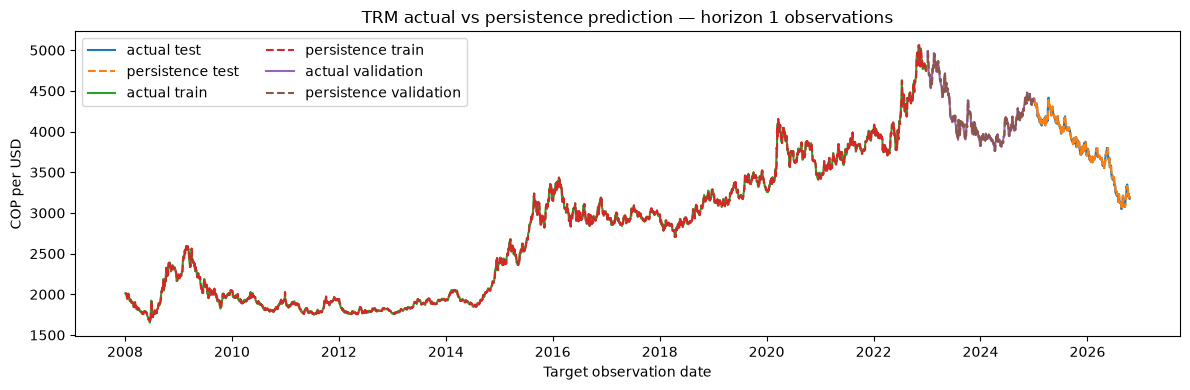

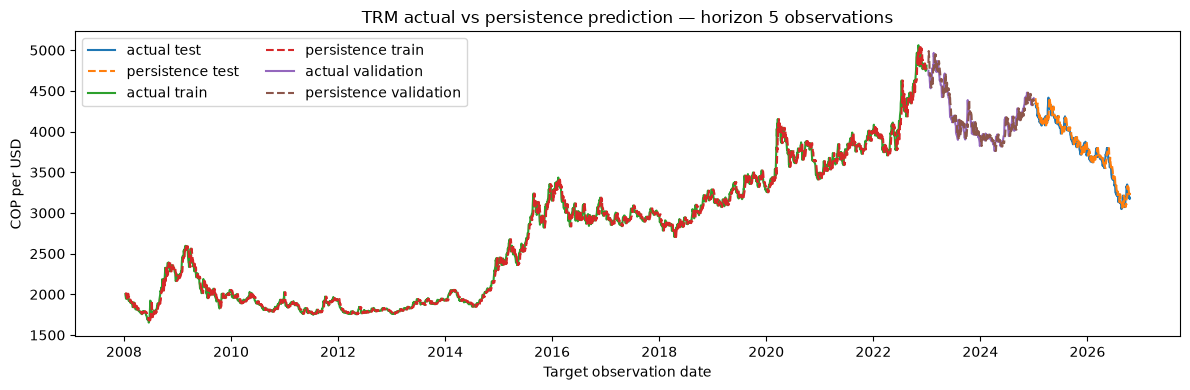

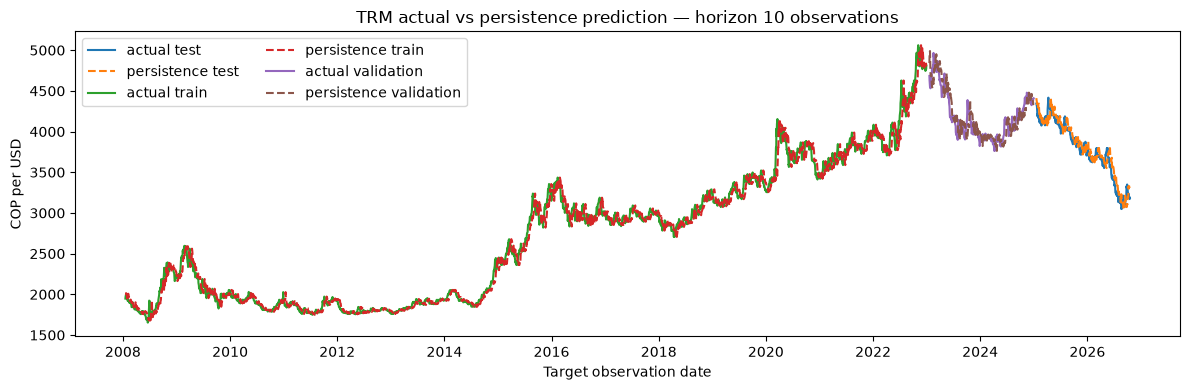

In [3]:
for horizon in (1, 5, 10):
    selected = predictions[predictions["horizon"] == horizon]
    fig, ax = plt.subplots(figsize=(12, 4))
    for partition, group in selected.groupby("partition"):
        ax.plot(pd.to_datetime(group["target_date"]), group["actual"], label=f"actual {partition}")
        ax.plot(pd.to_datetime(group["target_date"]), group["prediction"], linestyle="--", label=f"persistence {partition}")
    ax.set_title(f"TRM actual vs persistence prediction — horizon {horizon} observations")
    ax.set_xlabel("Target observation date")
    ax.set_ylabel("COP per USD")
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()

## Interpretation and limitations

A horizon is the number of subsequent TRM observations, not a guaranteed number of calendar or business days. Weekend, holiday, and validity-date conventions remain in the observed index; no observations are fabricated.

The baseline is a necessary reference: a more complex model should demonstrate improvement against it under identical origins and targets. Beating persistence on MAE/RMSE alone does not establish business value, operational usefulness, or stability under future market regimes. The historical source does not provide original publication vintages, so the as-of cutoff excludes known future-dated observations but cannot reconstruct all information that was available at each historical origin.